# Segmentación de Clientes mediante K-Means

## Objetivo

Identificar grupos de clientes con comportamientos
similares de compra y uso del sitio web, utilizando
el algoritmo K-Means, sin contar con etiquetas previas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## 1. Carga y exploración del dataset

En esta etapa se carga el conjunto de datos y se realiza
una exploración inicial para conocer su estructura,
las variables disponibles y la cantidad de registros.

In [2]:
# Cargar el dataset desde la carpeta data
df = pd.read_csv("data/dataset_segmentacion_clientes.csv")

# Mostrar las primeras cinco filas
df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


In [3]:
# Cantidad de filas y columnas
print("Dimensiones del dataset:", df.shape)

Dimensiones del dataset: (700, 7)


In [4]:
# Información general del dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   purchase_freq_month   700 non-null    float64
 1   avg_basket_usd        700 non-null    float64
 2   time_on_site_min      700 non-null    float64
 3   discount_sensitivity  700 non-null    float64
 4   returns_rate          700 non-null    float64
 5   noise_gauss           700 non-null    float64
 6   noise_uniform         700 non-null    float64
dtypes: float64(7)
memory usage: 38.4 KB


In [5]:
# Verificar valores faltantes
df.isnull().sum()

purchase_freq_month     0
avg_basket_usd          0
time_on_site_min        0
discount_sensitivity    0
returns_rate            0
noise_gauss             0
noise_uniform           0
dtype: int64

### Análisis exploratorio

El dataset contiene 700 registros y 7 variables numéricas.

Se verificó que no existen valores faltantes,
por lo que no es necesario realizar un tratamiento
de datos nulos.

Para aplicar K-Means se seleccionarán las cinco
variables de comportamiento indicadas,
excluyendo las dos variables adicionales de ruido.

## 2. Selección de variables

Para realizar la segmentación de clientes se seleccionan
cinco variables relacionadas con sus comportamientos
de compra y uso del sitio web.

Se excluyen las variables noise_gauss y noise_uniform,
ya que representan ruido y no aportan información
relevante sobre el comportamiento de los clientes.

In [6]:
# Seleccionar las variables para K-Means
variables = [
    "purchase_freq_month",
    "avg_basket_usd",
    "time_on_site_min",
    "discount_sensitivity",
    "returns_rate"
]

# Crear un DataFrame con las variables seleccionadas
X = df[variables].copy()

# Visualizar las primeras filas
X.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,11.152508,181.300834,33.564036,1.000000,0.800000
1,12.053451,178.637272,35.432081,0.784974,0.000000
2,2.203006,450.185298,7.030757,0.898297,0.000000
3,4.233314,89.006342,10.834453,0.000000,0.800000
4,1.716799,449.773982,7.254548,0.000000,0.003279


In [7]:
# Estadísticas descriptivas
X.describe().round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
count,700.00,700.00,700.00,700.00,700.00
mean,5.88,248.17,16.78,0.43,0.34
std,4.47,154.90,12.91,0.43,0.36
min,0.10,86.99,3.16,0.00,0.00
25%,2.28,90.77,6.60,0.00,0.00
50%,4.13,180.22,9.97,0.30,0.17
75%,11.21,449.72,34.34,1.00,0.80
max,14.60,452.97,38.35,1.00,0.80


### Interpretación de los datos

El análisis estadístico permite observar diferencias
en las escalas de las variables seleccionadas.

Por ejemplo, el ticket promedio se expresa en dólares,
mientras que la sensibilidad a descuentos y la tasa
de devoluciones utilizan valores entre 0 y 1.

Estas diferencias pueden afectar el cálculo de
distancias que realiza K-Means.

Por este motivo, será necesario aplicar un escalado
de variables antes de entrenar el modelo.

## 3. Escalado de variables

Antes de aplicar K-Means, se realiza un escalado
de las variables mediante StandardScaler.


In [8]:
# Crear el escalador
scaler = StandardScaler()

# Escalar las variables seleccionadas
X_scaled = scaler.fit_transform(X)

print("Variables escaladas correctamente")

Variables escaladas correctamente


In [9]:
# Convertir los datos escalados en un DataFrame
df_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

# Mostrar las primeras cinco filas
df_scaled.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,1.181048,-0.432012,1.300224,1.333423,1.298671
1,1.382696,-0.449219,1.444979,0.834706,-0.946196
2,-0.822026,1.305039,-0.755841,1.097540,-0.946196
3,-0.367604,-1.028253,-0.461093,-0.985910,1.298671
4,-0.930849,1.302382,-0.738500,-0.985910,-0.936996


In [10]:
# Comprobar la media y desviación estándar
print("Media de las variables escaladas:")
print(df_scaled.mean().round(2))

print("\nDesviación estándar:")
print(df_scaled.std(ddof=0).round(2))

Media de las variables escaladas:
purchase_freq_month    -0.0
avg_basket_usd         -0.0
time_on_site_min        0.0
discount_sensitivity    0.0
returns_rate           -0.0
dtype: float64

Desviación estándar:
purchase_freq_month     1.0
avg_basket_usd          1.0
time_on_site_min        1.0
discount_sensitivity    1.0
returns_rate            1.0
dtype: float64


### Interpretación del escalado

Se aplicó StandardScaler a las cinco variables
seleccionadas para la segmentación de clientes.

Se comprobó que las variables transformadas presentan
una media cercana a 0 y una desviación estándar
cercana a 1.

Este procedimiento permite aplicar K-Means evitando
que las diferencias de escala influyan de manera
desproporcionada en la formación de los clusters.

## 4. Determinación del número de clusters

Para identificar una cantidad razonable de segmentos,
se utiliza el método de codo.

Se comparan modelos K-Means con valores de k entre
2 y 6, analizando la inercia obtenida en cada caso.

El objetivo es identificar el punto a partir de cual
aumentar la cantidad de clusters produce mejoras
cada vez menores.

In [11]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.cluster")

# Lista para almacenar las inercias
inercias = []

# Probar diferentes cantidades de clusters
for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inercias.append(kmeans.inertia_)

print("Inercias calculadas correctamente")

Inercias calculadas correctamente


In [12]:
# Comparación de inercias
df_inercias = pd.DataFrame({
    "Número de clusters (k)": range(2, 7),
    "Inercia": inercias
})

df_inercias.round(2)

,Número de clusters (k),Inercia
0,2,2088.88
1,3,1408.70
2,4,1173.44
3,5,997.74
4,6,762.47


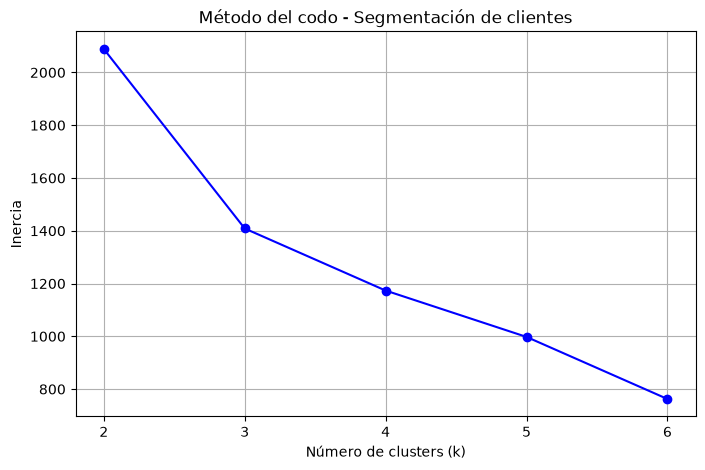

In [13]:
# Gráfico del método del codo

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 7),
    inercias,
    marker="o",
    linestyle="-",
    color="blue"
)

plt.title("Método del codo - Segmentación de clientes")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")

plt.xticks(range(2, 7))
plt.grid(True)

plt.show()

### Interpretación del método del codo

El gráfico muestra que la inercia disminuye a medida
que aumenta la cantidad de clusters.

La reducción más importante se observa entre k=2 y k=3.
A partir de este último valor, la disminución es menor,
aunque no se identifica un codo completamente definido.

Por este motivo, se considera que k=3 es una opción
razonable. Sin embargo, también se evaluará k=4
para determinar si permite identificar perfiles
de clientes más diferenciados.

### Evaluación mediante el índice de silueta

Para complementar el método del codo, se utiliza
el índice de silueta (Silhouette Score).

Esta métrica permite evaluar la cohesión de los
clientes dentro de cada cluster y la separación
entre los diferentes grupos.

Se comparan valores de k entre 2 y 6 para analizar
la calidad de los agrupamientos obtenidos.

In [14]:
from sklearn.metrics import silhouette_score

# Lista para guardar los índices de silueta
siluetas = []

# Evaluar diferentes cantidades de clusters
for k in range(2, 7):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, etiquetas)

    siluetas.append(score)

print("Índices de silueta calculados correctamente")

Índices de silueta calculados correctamente


In [15]:
# Comparación de inercia e índice de silueta

comparacion = pd.DataFrame({
    "Número de clusters (k)": range(2, 7),
    "Inercia": inercias,
    "Silhouette Score": siluetas
})

comparacion.round(3)

,Número de clusters (k),Inercia,Silhouette Score
0,2,2088.881,0.400
1,3,1408.702,0.431
2,4,1173.438,0.429
3,5,997.742,0.420
4,6,762.466,0.461


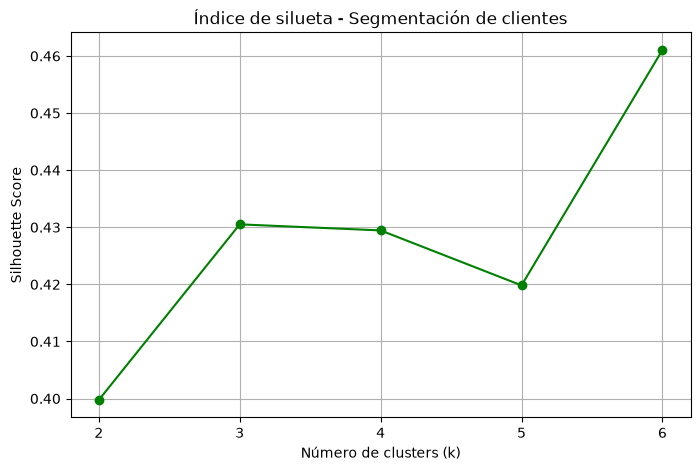

In [16]:
# Gráfico del índice de silueta

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 7),
    siluetas,
    marker="o",
    linestyle="-",
    color="green"
)

plt.title("Índice de silueta - Segmentación de clientes")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")

plt.xticks(range(2, 7))
plt.grid(True)

plt.show()

### Interpretación del índice de silhouette

El índice de silhouette presenta su valor más alto
para k=6 (0,461), lo que indica una mejor cohesión
y separación promedio de los grupos entre las
opciones evaluadas.

Sin embargo, los valores obtenidos para k=3 (0,431)
y k=4 (0,429) son muy similares.

Al considerar estos resultados junto con el método
del codo, no se identifica una única cantidad
óptima de clusters.

Se mantiene k=4 como una elección exploratoria,
ya que permite identificar perfiles de clientes
diferenciados, especialmente dos grupos de compradores
de alto valor con distintas tasas de devoluciones.

Por lo tanto, la elección de cuatro clusters se
fundamenta principalmente en la interpretabilidad
de los segmentos y no en el valor máximo del
índice de silhouette.

## 5. Aplicación del algoritmo K-Means

A partir de la evaluación realizada, se seleccionan
cuatro clusters para identificar diferentes perfiles
de clientes.

Se entrena el modelo K-Means utilizando las cinco
variables previamente escaladas. Posteriormente,
se analizan los centroides para interpretar las
características de cada segmento.

In [17]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.cluster")

# Crear el modelo K-Means con 4 clusters
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Entrenar el modelo y asignar clusters
clusters = kmeans_final.fit_predict(X_scaled)

# Agregar los clusters al DataFrame
df_resultado = X.copy()
df_resultado["Cluster"] = clusters

# Mostrar los primeros registros
df_resultado.head()



,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,Cluster
0,11.152508,181.300834,33.564036,1.000000,0.800000,0
1,12.053451,178.637272,35.432081,0.784974,0.000000,0
2,2.203006,450.185298,7.030757,0.898297,0.000000,3
3,4.233314,89.006342,10.834453,0.000000,0.800000,2
4,1.716799,449.773982,7.254548,0.000000,0.003279,3


### Distribución de clientes por cluster

Una vez aplicado K-Means, se analiza la cantidad
de clientes asignados a cada cluster.

Esto permite conocer cómo se distribuyen los
700 registros entre los cuatro grupos identificados.

In [18]:
# Contar los clientes de cada cluster
cantidad_clientes = df_resultado["Cluster"].value_counts().sort_index()

# Mostrar los resultados
cantidad_clientes

Cluster
0    230
1    121
2    220
3    129
Name: count, dtype: int64

### Interpretación

El algoritmo K-Means distribuyó los 700 clientes
en cuatro clusters.

Los grupos presentan diferentes cantidades de
integrantes, siendo los clusters 0 y 2 los más numerosos.

Esta distribución permite identificar el tamaño
de cada segmento, aunque todavía es necesario
analizar sus características para interpretar
los comportamientos de compra.

## 6. Análisis de los centroides

Para interpretar los clusters identificados
por K-Means, se analizan los centroides de
cada grupo.

Los centroides representan los valores promedio
de las variables utilizadas para la segmentación.

Este análisis permite identificar patrones
de comportamiento y describir los diferentes
perfiles de clientes.

In [19]:
# Obtener los centroides en la escala original
centroides_originales = scaler.inverse_transform(
    kmeans_final.cluster_centers_
)

# Crear un DataFrame con los centroides
df_centroides = pd.DataFrame(
    centroides_originales,
    columns=X.columns
)

# Mostrar los centroides
df_centroides.round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,11.96,180.00,35.02,0.54,0.33
1,1.80,450.03,6.07,0.36,0.73
2,4.09,89.96,10.00,0.38,0.30
3,1.89,450.21,5.89,0.36,0.04


### Interpretación de los segmentos identificados

A partir del análisis de los centroides se identificaron
cuatro perfiles de clientes:

**Cluster 0 - Compradores frecuentes:**
Presentan una frecuencia elevada de compras mensuales,
un ticket promedio de 180 USD y mayor tiempo de
permanencia en el sitio web.

**Cluster 1 - Compradores de alto valor con muchas devoluciones:**
Realizan compras poco frecuentes, con un ticket promedio
de 450 USD y una tasa de devoluciones elevada (73 %).

**Cluster 2 - Compradores de ticket bajo:**
Realizan aproximadamente cuatro compras mensuales,
con un ticket promedio de 90 USD y una permanencia
moderada en el sitio web.

**Cluster 3 - Compradores de alto valor con pocas devoluciones:**
Realizan compras poco frecuentes, con un ticket promedio
de 450 USD y una tasa de devoluciones muy baja (4 %).

Los resultados muestran que los clusters 1 y 3
presentan valores de compra similares, pero se
diferencian principalmente por la tasa de devoluciones.

Esta diferencia permite justificar la elección
de cuatro clusters para identificar perfiles
de clientes más específicos.

## 7. Visualización de los clusters

Se realiza un gráfico de dispersión para visualizar
la distribución de los clientes según su frecuencia
de compras mensuales y el ticket promedio.

Los diferentes colores representan los cuatro
clusters identificados mediante K-Means.

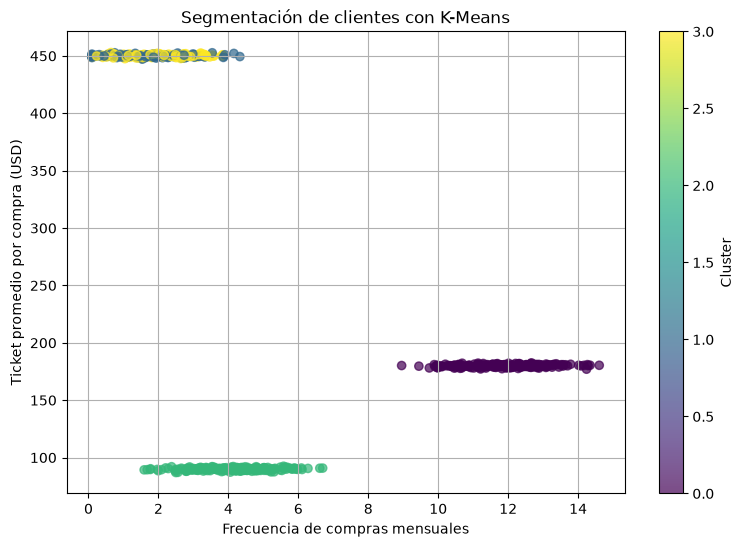

In [20]:
# Gráfico de dispersión de los clusters

plt.figure(figsize=(9, 6))

plt.scatter(
    df_resultado["purchase_freq_month"],
    df_resultado["avg_basket_usd"],
    c=df_resultado["Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.title("Segmentación de clientes con K-Means")
plt.xlabel("Frecuencia de compras mensuales")
plt.ylabel("Ticket promedio por compra (USD)")

plt.colorbar(label="Cluster")
plt.grid(True)

plt.show()

### Interpretación del gráfico de dispersión

El gráfico permite visualizar la distribución de los
clientes según la frecuencia de compras mensuales
y el ticket promedio.

Se observan tres conjuntos de puntos claramente
diferenciados, aunque K-Means identificó cuatro clusters.

Los clusters 1 y 3 presentan valores similares de
frecuencia de compra y ticket promedio, por lo que
aparecen superpuestos en esta representación.

Sin embargo, el análisis de los centroides mostró
que ambos grupos se diferencian principalmente por
la tasa de devoluciones.

Esto demuestra la importancia de considerar las
cinco variables para identificar patrones de
comportamiento que no pueden observarse al
representar solamente dos características.

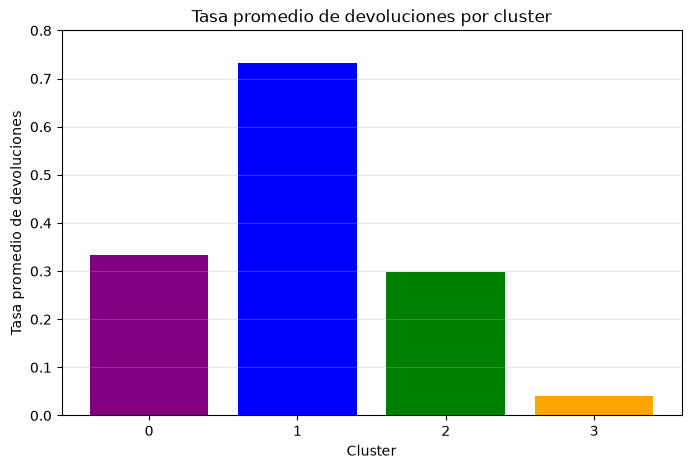

In [21]:
# Calcular la tasa promedio de devoluciones por cluster
devoluciones = df_resultado.groupby("Cluster")["returns_rate"].mean()

# Crear gráfico de barras
plt.figure(figsize=(8, 5))

plt.bar(
    devoluciones.index,
    devoluciones.values,
    color=["purple", "blue", "green", "orange"]
)

plt.title("Tasa promedio de devoluciones por cluster")
plt.xlabel("Cluster")
plt.ylabel("Tasa promedio de devoluciones")

plt.xticks(range(4))
plt.ylim(0, 0.8)
plt.grid(axis="y", alpha=0.3)

plt.show()

### Interpretación de la tasa de devoluciones

El gráfico muestra diferencias en la tasa promedio
de devoluciones de los cuatro segmentos identificados.

El cluster 1 presenta la tasa más elevada (73 %),
mientras que el cluster 3 registra la menor (4 %).

Aunque ambos grupos realizan compras de alto valor,
sus comportamientos respecto de las devoluciones
son diferentes.

Este resultado permite identificar perfiles más
específicos y respalda la elección de cuatro clusters
para la segmentación de clientes.

## 8. Conclusión

En este trabajo se aplicó el algoritmo K-Means para identificar
segmentos de clientes según sus comportamientos de compra y uso
del sitio web, utilizando cinco variables previamente escaladas
con StandardScaler.

Para determinar la cantidad de clusters se compararon valores
de k entre 2 y 6 mediante el método del codo y el índice de
silueta. La inercia mostró su mayor reducción entre k=2 y k=3,
aunque sin presentar un codo completamente definido. Por su
parte, el índice de silueta alcanzó su valor más alto con k=6
(0,461), mientras que k=3 (0,431) y k=4 (0,429) obtuvieron
resultados muy similares.

Considerando ambas métricas, se seleccionó k=4 como una
alternativa exploratoria, priorizando la interpretación de los
perfiles de clientes. Esta elección no representa necesariamente
la mejor puntuación numérica, pero permite identificar segmentos
con características diferenciadas.

El análisis de los centroides permitió reconocer cuatro perfiles:
compradores frecuentes, compradores de ticket bajo y dos grupos
de compradores de alto valor. Estos últimos presentan frecuencias
y montos de compra similares, pero se diferencian principalmente
por sus tasas de devoluciones: aproximadamente 73 % en el
cluster 1 y 4 % en el cluster 3.

Los gráficos confirmaron estas diferencias y mostraron que
considerar múltiples variables permite identificar patrones
que no se observan al analizar solamente la frecuencia y el
valor de compra.

En conclusión, K-Means permitió reconocer patrones de
comportamiento sin etiquetas previas. Los segmentos obtenidos
podrían orientar estrategias comerciales diferenciadas, aunque
sería necesario realizar análisis adicionales para confirmar
su estabilidad y utilidad en situaciones reales.